# Task 3: Recommendation System Analysis

**Goal:** build a content-based recommender that suggests similar Netflix titles using each title's attributes, then evaluate how good the recommendations are.

**Workflow**
1. Extract relevant content features
2. Perform text preprocessing
3. Calculate content similarity
4. Generate recommendations for selected titles
5. Evaluate recommendation quality

**Approach:** content-based filtering. There is no user viewing data, so similarity is based on what a title *is* (genres, director, country, type, audience, era), not on who watched it.

**Input:** `netflix_cleaned.csv` from Task 1.

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "figure.dpi": 110,
})

df = pd.read_csv("netflix_cleaned.csv").reset_index(drop=True)
print("Titles:", len(df), "| Unique titles:", df["title"].nunique())

Titles: 8786 | Unique titles: 8786


## Step 1: Extract relevant content features

**What is available.** This version of the dataset has no plot `description` or `cast` column, which are what most Netflix recommenders rely on. The usable content features are:

| Feature | Why it helps | Caveat |
|---|---|---|
| `listed_in` (genres) | Strongest signal of what a title is about | Broad tags (e.g. "International Movies") |
| `director` | Same director often means similar style | Missing for about 29% of titles, mostly TV |
| `country` | Captures language and cultural style | One country per title |
| `type` | Movie vs TV Show is a basic viewer preference | |
| `audience` | Keeps kids' content away from adult content | |
| `release_year` (as decade) | Era and production style | |

Title text is **not** used: titles rarely describe content ("Ozark" says nothing about crime drama).

In [2]:
features = df[["title", "type", "listed_in", "director", "country", "audience", "release_year"]].copy()
features.head()

,title,type,listed_in,director,country,audience,release_year
0,Dick Johnson Is Dead,Movie,Documentaries,Kirsten Johnson,United States,Teens,2020
1,Ganglands,TV Show,"Crime TV Shows, International TV Shows, TV Act...",Julien Leclercq,France,Adults,2021
2,Midnight Mass,TV Show,"TV Dramas, TV Horror, TV Mysteries",Mike Flanagan,United States,Adults,2021
3,Confessions of an Invisible Girl,Movie,"Children & Family Movies, Comedies",Bruno Garotti,Brazil,Older Kids,2021
4,Sankofa,Movie,"Dramas, Independent Movies, International Movies",Haile Gerima,United States,Adults,1993


## Step 2: Text preprocessing

These fields are lists of names, not sentences, so the preprocessing focuses on making each name a single clean token:
- lowercase everything
- split multi-value fields on commas (`"Dramas, Thrillers"` becomes two genres)
- join multi-word names into one token, so `"Rajiv Chilaka"` is one director, not two words, and `"International Movies"` does not match `"International TV Shows"` on the word "International"
- drop `"Unknown"` so missing values do not make unrelated titles look similar
- convert release year to a decade token

In [3]:
def to_tokens(value, split=True):
    """Turn a field into a space-separated string of single-word tokens."""
    if pd.isna(value):
        return ""
    items = str(value).split(",") if split else [str(value)]
    tokens = []
    for item in items:
        item = item.strip().lower()
        if not item or item == "unknown":
            continue
        tokens.append(re.sub(r"[^a-z0-9]+", "_", item).strip("_"))
    return " ".join(tokens)

features["genre_tokens"] = features["listed_in"].apply(to_tokens)
features["director_tokens"] = features["director"].apply(to_tokens)
features["country_tokens"] = features["country"].apply(to_tokens, split=False)
features["type_tokens"] = features["type"].apply(to_tokens, split=False)
features["audience_tokens"] = features["audience"].apply(to_tokens, split=False)
features["decade_tokens"] = (features["release_year"] // 10 * 10).astype(str) + "s"

token_cols = ["genre_tokens", "director_tokens", "country_tokens",
              "type_tokens", "audience_tokens", "decade_tokens"]
features[["title"] + token_cols].head()

,title,genre_tokens,director_tokens,country_tokens,type_tokens,audience_tokens,decade_tokens
0,Dick Johnson Is Dead,documentaries,kirsten_johnson,united_states,movie,teens,2020s
1,Ganglands,crime_tv_shows international_tv_shows tv_actio...,julien_leclercq,france,tv_show,adults,2020s
2,Midnight Mass,tv_dramas tv_horror tv_mysteries,mike_flanagan,united_states,tv_show,adults,2020s
3,Confessions of an Invisible Girl,children_family_movies comedies,bruno_garotti,brazil,movie,older_kids,2020s
4,Sankofa,dramas independent_movies international_movies,haile_gerima,united_states,movie,adults,1990s


## Step 3: Calculate content similarity

**Method**
1. Convert each feature group into a TF-IDF matrix. TF-IDF gives rare tokens more weight than common ones, so sharing a niche genre like "Anime Features" counts for more than sharing "Dramas".
2. Weight each group by how much it should matter, then stack the groups side by side.
3. Compare titles with **cosine similarity**, computed per feature group and combined as a weighted average (1 = identical on every feature, 0 = nothing in common).

**Design note:** an earlier version normalized the combined vector instead. That quietly gave titles with a missing director *higher* similarity scores, because their genre and country features got a bigger share of the vector. Scoring each feature separately and averaging fixes this.

**Weights:** genres matter most, then director and country. These were chosen by judgment and then checked in Step 5.

In [4]:
WEIGHTS = {
    "genre_tokens": 1.0,
    "director_tokens": 0.6,
    "country_tokens": 0.5,
    "type_tokens": 0.5,
    "audience_tokens": 0.4,
    "decade_tokens": 0.2,
}

def build_matrix(weights):
    # Each block is scaled by sqrt(weight / total weight), so the dot product of two rows is
    # a weighted average of the per-feature cosine similarities. A missing feature (e.g. no
    # director) then simply contributes 0, instead of inflating the other features.
    total = sum(weights.values())
    blocks = []
    for col, w in weights.items():
        if w == 0:
            continue
        vec = TfidfVectorizer(token_pattern=r"[^ ]+", lowercase=False)
        Xb = normalize(vec.fit_transform(features[col]))   # each row has length 1 (or 0 if empty)
        blocks.append(Xb * np.sqrt(w / total))
    return hstack(blocks).tocsr()

X = build_matrix(WEIGHTS)
print("Feature matrix:", X.shape, "(titles x tokens)")

Feature matrix: (8786, 5131) (titles x tokens)


In [5]:
# Cosine similarity of one title against all others (computed on demand to save memory:
# a full 8,786 x 8,786 matrix would need about 600 MB)
def similarities(idx, matrix=X):
    return (matrix @ matrix[idx].T).toarray().ravel()

idx = df.index[df["title"] == "Narcos"][0]
sims = similarities(idx)
print("Similarity of Narcos to itself:", round(sims[idx], 3), "(below 1 because Narcos has no director listed)")
print("Average similarity to the rest of the catalog:", round(np.delete(sims, idx).mean(), 3))

Similarity of Narcos to itself: 0.812 (below 1 because Narcos has no director listed)
Average similarity to the rest of the catalog: 0.22


## Step 4: Generate recommendations

Many titles share identical profiles (same genres, country, type), which creates ties. Ties are broken by closeness in release year, so a 2019 drama is preferred over a 1985 drama with the same score.

In [6]:
title_to_idx = pd.Series(df.index, index=df["title"])

def recommend_idx(idx, n=10, matrix=X):
    sims = similarities(idx, matrix)
    year_gap = np.abs(df["release_year"].values - df.at[idx, "release_year"])
    order = np.lexsort((year_gap, -np.round(sims, 4)))   # sort by similarity, then year gap
    order = order[order != idx]
    return order[:n], sims[order[:n]]

def recommend(title, n=10, matrix=X):
    if title not in title_to_idx:
        matches = df.loc[df["title"].str.contains(title, case=False, regex=False), "title"].head(5).tolist()
        raise ValueError(f"'{title}' not found. Close matches: {matches}")
    idx = title_to_idx[title]
    rec_idx, scores = recommend_idx(idx, n, matrix)
    query_genres = set(df.at[idx, "listed_in"].split(", "))
    out = df.loc[rec_idx, ["title", "type", "release_year", "country", "director", "listed_in"]].copy()
    out.insert(1, "similarity", scores.round(3))
    out["shared_genres"] = out["listed_in"].apply(lambda g: ", ".join(sorted(query_genres & set(g.split(", ")))))
    return out.drop(columns="listed_in").reset_index(drop=True)

def show_query(title):
    r = df.loc[title_to_idx[title]]
    print(f"{title} | {r['type']} | {r['release_year']} | {r['country']} | {r['director']}")
    print(f"Genres: {r['listed_in']}")

A test set of titles chosen to cover different types, countries and audiences:

In [7]:
show_query("Narcos")
recommend("Narcos")

Narcos | TV Show | 2017 | United States | Unknown
Genres: Crime TV Shows, TV Action & Adventure, TV Dramas


,title,similarity,type,release_year,country,director,shared_genres
0,Marvel's The Defenders,0.812,TV Show,2017,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"
1,Queen of the South,0.812,TV Show,2018,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"
2,Marvel's Iron Fist,0.812,TV Show,2018,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"
3,Marvel's Luke Cage,0.812,TV Show,2018,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"
4,Gotham,0.812,TV Show,2019,United States,Danny Cannon,"Crime TV Shows, TV Action & Adventure, TV Dramas"
5,Marvel's Jessica Jones,0.812,TV Show,2019,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"
6,Marvel's Daredevil,0.774,TV Show,2018,United States,Unknown,"Crime TV Shows, TV Action & Adventure"
7,Marco Polo,0.762,TV Show,2016,United States,Unknown,"TV Action & Adventure, TV Dramas"
8,Spartacus,0.762,TV Show,2013,United States,Unknown,"TV Action & Adventure, TV Dramas"
9,Altered Carbon,0.750,TV Show,2020,United States,Unknown,"Crime TV Shows, TV Action & Adventure, TV Dramas"


In [8]:
show_query("The Irishman")
recommend("The Irishman")

The Irishman | Movie | 2019 | United States | Martin Scorsese
Genres: Dramas


,title,similarity,type,release_year,country,director,shared_genres
0,Gangs of New York,0.938,Movie,2002,United States,Martin Scorsese,Dramas
1,Working Title,0.813,Movie,2019,United States,Mary Harron,Dramas
2,Burning Cane,0.813,Movie,2019,United States,Phillip Youmans,Dramas
3,American Son,0.813,Movie,2019,United States,Kenny Leon,Dramas
4,The Highwaymen,0.813,Movie,2019,United States,John Lee Hancock,Dramas
5,American Warfighter,0.813,Movie,2019,United States,Jerry G. Angelo,Dramas
6,Black & Privileged: Volume 1,0.813,Movie,2019,United States,Mark Harris,Dramas
7,Goldie,0.813,Movie,2019,United States,Sam de Jong,Dramas
8,Saving Zoë,0.813,Movie,2019,United States,Jeffrey G. Hunt,Dramas
9,SGT. Will Gardner,0.813,Movie,2019,United States,Max Martini,Dramas


In [9]:
show_query("Naruto")
recommend("Naruto")

Naruto | TV Show | 2006 | Japan | Hayato Date
Genres: Anime Series, International TV Shows


,title,similarity,type,release_year,country,director,shared_genres
0,Bleach,0.813,TV Show,2006,Japan,Unknown,"Anime Series, International TV Shows"
1,Gurren Lagann,0.813,TV Show,2007,Japan,Unknown,"Anime Series, International TV Shows"
2,Soul Eater,0.813,TV Show,2008,Japan,Unknown,"Anime Series, International TV Shows"
3,Fullmetal Alchemist,0.813,TV Show,2003,Japan,Unknown,"Anime Series, International TV Shows"
4,InuYasha,0.813,TV Show,2001,Japan,Unknown,"Anime Series, International TV Shows"
5,ONE PIECE,0.770,TV Show,2002,Japan,Unknown,Anime Series
6,DEATH NOTE,0.757,TV Show,2006,Japan,Unknown,"Anime Series, International TV Shows"
7,Toradora!,0.752,TV Show,2008,Japan,Unknown,"Anime Series, International TV Shows"
8,Vampire Knight,0.752,TV Show,2008,Japan,Unknown,"Anime Series, International TV Shows"
9,Fullmetal Alchemist: Brotherhood,0.750,TV Show,2010,Japan,Yasuhiro Irie,"Anime Series, International TV Shows"


In [10]:
show_query("Kota Factory")
recommend("Kota Factory")

Kota Factory | TV Show | 2021 | India | Unknown
Genres: International TV Shows, Romantic TV Shows, TV Comedies


,title,similarity,type,release_year,country,director,shared_genres
0,Bhaag Beanie Bhaag,0.813,TV Show,2020,India,Unknown,"International TV Shows, Romantic TV Shows, TV ..."
1,Mismatched,0.813,TV Show,2020,India,Unknown,"International TV Shows, Romantic TV Shows, TV ..."
2,Taj Mahal 1989,0.813,TV Show,2020,India,Unknown,"International TV Shows, Romantic TV Shows, TV ..."
3,Little Things,0.750,TV Show,2019,India,Unknown,"International TV Shows, Romantic TV Shows, TV ..."
4,College Romance,0.750,TV Show,2018,India,Unknown,"International TV Shows, Romantic TV Shows, TV ..."
5,Masaba Masaba,0.689,TV Show,2020,India,Unknown,"International TV Shows, TV Comedies"
6,Hasmukh,0.680,TV Show,2020,India,Unknown,"International TV Shows, TV Comedies"
7,Engineering Girls,0.672,TV Show,2018,India,Unknown,"International TV Shows, TV Comedies"
8,Inmates,0.672,TV Show,2017,India,Unknown,"International TV Shows, TV Comedies"
9,Feels Like Ishq,0.656,TV Show,2021,Pakistan,Unknown,"International TV Shows, Romantic TV Shows, TV ..."


In [11]:
show_query("Dick Johnson Is Dead")
recommend("Dick Johnson Is Dead")

Dick Johnson Is Dead | Movie | 2020 | United States | Kirsten Johnson
Genres: Documentaries


,title,similarity,type,release_year,country,director,shared_genres
0,The Last Blockbuster,0.813,Movie,2020,United States,Taylor Morden,Documentaries
1,Giving Voice,0.813,Movie,2020,United States,"James D. Stern, Fernando Villena",Documentaries
2,The Social Dilemma,0.813,Movie,2020,United States,Jeff Orlowski,Documentaries
3,The Claudia Kishi Club,0.813,Movie,2020,United States,Sue Ding,Documentaries
4,The Reason I Jump,0.813,Movie,2021,United States,Jerry Rothwell,Documentaries
5,Amy Tan: Unintended Memoir,0.813,Movie,2021,United States,James Redford,Documentaries
6,Seaspiracy,0.813,Movie,2021,United States,Ali Tabrizi,Documentaries
7,What Would Sophia Loren Do?,0.813,Movie,2021,United States,Ross Kauffman,Documentaries
8,Creating The Queen's Gambit,0.813,Movie,2021,United States,Unknown,Documentaries
9,The Minimalists: Less Is Now,0.813,Movie,2021,United States,Unknown,Documentaries


**Observations**
- Recommendations stay within the right type, genre family and audience: crime and action TV for *Narcos*, anime for *Naruto*, Indian comedy and romance series for *Kota Factory*, recent US documentaries for *Dick Johnson Is Dead*.
- The director feature works when directors repeat: *Gangs of New York* (also Scorsese) is the top match for *The Irishman*.
- The limits show in the same example. *The Irishman* has only one genre tag ("Dramas"), so after the Scorsese film, nine US dramas tie on the same score and the year tie-break picks whatever was released in 2019. Without plot descriptions, the model cannot tell a crime epic from a family drama.

## Step 5: Evaluate recommendation quality

There is no viewing data, so there are no "correct answers" to score against. Instead, the model is evaluated with standard **offline proxy metrics** over a random sample of 1,000 titles, and compared against two baselines:

| Metric | What it measures | Good value |
|---|---|---|
| Genre overlap (Jaccard) | Share of genres in common between a title and its recommendations | Higher |
| Same type rate | Recommending Movies for Movies, TV for TV | Higher |
| Same audience rate | Keeping kids' and adult content apart | Higher |
| Catalog coverage | Share of the catalog that ever gets recommended | Higher (avoids recommending the same few titles) |
| Intra-list similarity | How alike the 10 recommendations are to each other | Not too close to 1 (some variety is good) |

**Models compared**
- **Random:** 10 random titles (the floor)
- **Genre only:** TF-IDF on genres alone
- **Weighted (final):** all features with the weights above

In [12]:
rng = np.random.default_rng(42)
sample = rng.choice(len(df), size=1000, replace=False)
N = 10

genre_sets = df["listed_in"].str.split(", ").apply(set).values
types = df["type"].values
audiences = df["audience"].values

def jaccard(a, b):
    return len(a & b) / len(a | b)

def evaluate(get_recs, matrix=None):
    g, t, a, ils, recommended = [], [], [], [], set()
    for i in sample:
        recs = get_recs(i)
        recommended.update(recs)
        g.append(np.mean([jaccard(genre_sets[i], genre_sets[j]) for j in recs]))
        t.append(np.mean(types[recs] == types[i]))
        a.append(np.mean(audiences[recs] == audiences[i]))
        if matrix is not None:
            S = (matrix[recs] @ matrix[recs].T).toarray()
            ils.append(S[np.triu_indices(N, 1)].mean())
    return {
        "Genre overlap": np.mean(g),
        "Same type rate": np.mean(t),
        "Same audience rate": np.mean(a),
        "Catalog coverage": len(recommended) / len(df),
        "Intra-list similarity": np.mean(ils) if ils else np.nan,
    }

X_genre = build_matrix({"genre_tokens": 1.0})

def random_recs(i):
    return rng.choice(np.delete(np.arange(len(df)), i), N, replace=False)

results = pd.DataFrame({
    "Random": evaluate(random_recs, X),
    "Genre only": evaluate(lambda i: recommend_idx(i, N, X_genre)[0], X),
    "Weighted (final)": evaluate(lambda i: recommend_idx(i, N, X)[0], X),
}).T.round(3)
results

,Genre overlap,Same type rate,Same audience rate,Catalog coverage,Intra-list similarity
Random,0.089,0.584,0.321,0.682,0.222
Genre only,0.966,1.000,0.497,0.573,0.644
Weighted (final),0.864,1.000,0.936,0.630,0.735


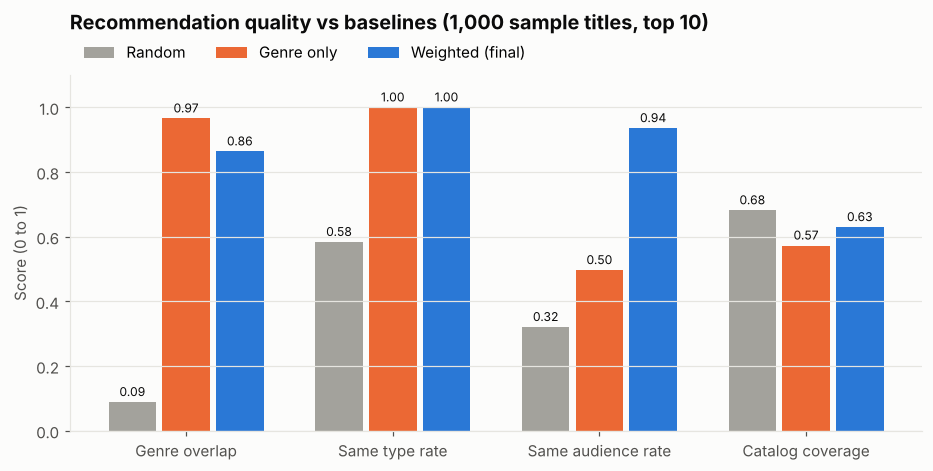

In [13]:
metrics = ["Genre overlap", "Same type rate", "Same audience rate", "Catalog coverage"]
colors = {"Random": GRAY, "Genre only": ORANGE, "Weighted (final)": BLUE}

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(metrics)); w = 0.26
for k, model in enumerate(results.index):
    bars = ax.bar(x + (k - 1) * w, results.loc[model, metrics], width=w - 0.03,
                  color=colors[model], label=model)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK, padding=2)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score (0 to 1)")
ax.set_title("Recommendation quality vs baselines (1,000 sample titles, top 10)", loc="left", pad=30)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.savefig("recommendation_evaluation.png", bbox_inches="tight", dpi=150)
plt.show()

**Reading the results**
- Both content models are far better than random on every relevance metric, so the features carry real signal.
- **Same type rate is 100% for both models.** Netflix uses separate genre tags for TV and film ("TV Dramas" vs "Dramas"), so genres alone already separate the two types.
- **Genre only** has the highest genre overlap (0.97), because that is all it optimizes. But it matches the audience only about half the time, so a kids' comedy can be followed by an adult comedy.
- **Weighted** trades some genre overlap (0.86) for much better audience matching (0.94 vs 0.50) and wider catalog coverage (63% vs 57%). For a real viewer, that is the better balance.
- Its intra-list similarity is higher, meaning each list of 10 is fairly uniform. That is expected for content-based systems and is noted as a limitation.

In [14]:
# Sensitivity check: does the result depend heavily on the director/country weights?
rows = {}
for label, change in {"No director": {"director_tokens": 0},
                      "No country": {"country_tokens": 0},
                      "Final weights": {}}.items():
    Xs = build_matrix({**WEIGHTS, **change})
    rows[label] = evaluate(lambda i: recommend_idx(i, N, Xs)[0], Xs)
pd.DataFrame(rows).T[["Genre overlap", "Same type rate", "Same audience rate", "Catalog coverage"]].round(3)

,Genre overlap,Same type rate,Same audience rate,Catalog coverage
No director,0.870,1.0,0.948,0.628
No country,0.909,1.0,0.975,0.624
Final weights,0.864,1.0,0.936,0.630


**Reading the sensitivity check**
- Removing **director** barely changes the scores. Most directors have only one or two titles, so the feature rarely fires, but it helps in specific cases like *The Irishman*.
- Removing **country** actually raises genre overlap and audience matching. Country pulls in regional titles that share fewer genre tags. Keeping it is a product decision: it favors recommending Indian series to someone watching an Indian series, at a small cost on these metrics. Either choice is defensible; the final model keeps it.

## Summary

**What was built:** a content-based recommender using TF-IDF on genres, director, country, type, audience and release decade, with cosine similarity and a release-year tie-break. Given any title, it returns the 10 most similar titles and the genres they share.

**How well it works**
- Recommendations clearly beat random and stay consistent in type, genre family and audience.
- Weighting several features gives a better balance than genres alone: slightly lower genre overlap, but much better audience matching (94% vs 50%) and more of the catalog recommended.
- A weighting bug (missing directors inflating scores) was found during testing and fixed by scoring each feature separately.

**Limitations**
- No plot descriptions or cast in this dataset, so the model cannot distinguish stories within a genre. Adding descriptions with TF-IDF or sentence embeddings would be the biggest improvement.
- The evaluation uses proxy metrics. Real quality can only be measured with user behavior (clicks, watch time) or an A/B test.
- Content-based systems recommend "more of the same" and cannot learn individual taste. A production system would combine this with collaborative filtering once viewing data exists.